# IVIS - re-treino do YOLO11 (dataset com mais fotos com mão)

**Antes de rodar:**
1. `Ambiente de execução` -> `Alterar o tipo de ambiente de execução` -> escolha **GPU (T4)**.
2. Chave do Roboflow: painel da esquerda, ícone de chave (**Secrets**) -> adicione um segredo chamado
   `ROBOFLOW_API_KEY` com a chave e ative "Acesso ao notebook".

Depois é só rodar as células de cima para baixo. No final ele baixa o `best_vN.pt`.

In [1]:
%pip install -q ultralytics roboflow

import os
HOME = os.getcwd()
print(HOME)

/content


In [2]:
from google.colab import userdata
from roboflow import Roboflow

VERSAO = 3

rf = Roboflow(api_key=userdata.get("ROBOFLOW_API_KEY"))
projeto = rf.workspace("julias-workspace-phzrr").project("pi-vi-ivis")
dataset = projeto.version(VERSAO).download("yolov11")
print("Dataset em:", dataset.location)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to PI-VI---IVIS-3 in yolov11:: 100%|██████████| 1719/1719 [00:00<00:00, 4669.25it/s]

Dataset em: /content/PI-VI---IVIS-3


In [3]:
from ultralytics import YOLO

modelo = YOLO("yolo11n.pt")
modelo.train(data=f"{dataset.location}/data.yaml", epochs=50, imgsz=512, batch=16)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.190 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/PI-VI---IVIS-3/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7eb60cab6b30>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [4]:
import glob

# pega o best.pt do treino mais recente
PESOS = max(glob.glob(f"{HOME}/runs/detect/train*/weights/best.pt"), key=os.path.getmtime)
print("Pesos:", PESOS)

best = YOLO(PESOS)
m = best.val(data=f"{dataset.location}/data.yaml", split="test")
print("Precisão:", m.box.mp, "| Revocação:", m.box.mr, "| mAP50:", m.box.map50, "| mAP50-95:", m.box.map)

Pesos: /content/runs/detect/train/weights/best.pt
Ultralytics 8.4.190 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 906.0±326.8 MB/s, size: 25.1 KB)
val: Scanning /content/PI-VI---IVIS-3/test/labels... 30 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 30/30 1.9Kit/s 0.0s
val: New cache created: /content/PI-VI---IVIS-3/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.0it/s 1.0s
                   all         30         30      0.998          1      0.995      0.912
Speed: 4.7ms preprocess, 14.8ms inference, 0.0ms loss, 1.9ms postprocess per image
Results saved to /content/runs/detect/val
Precisão: 0.9981241707808988 | Revocação: 1.0 | mAP50: 0.995 | mAP50-95: 0.9116585714285714


Results saved to /content/runs/detect/predict


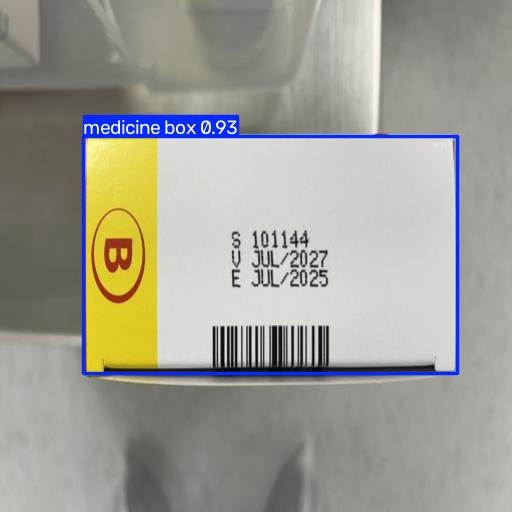

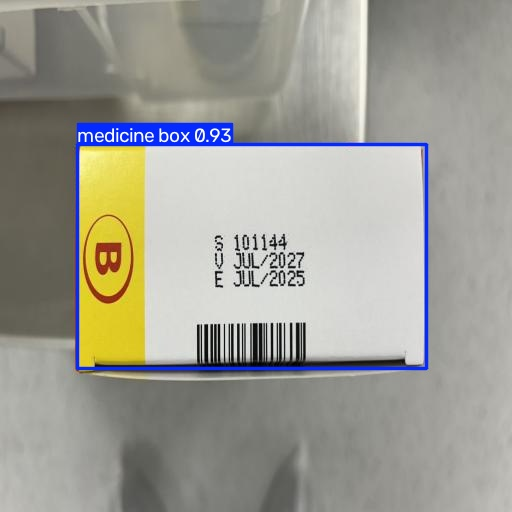

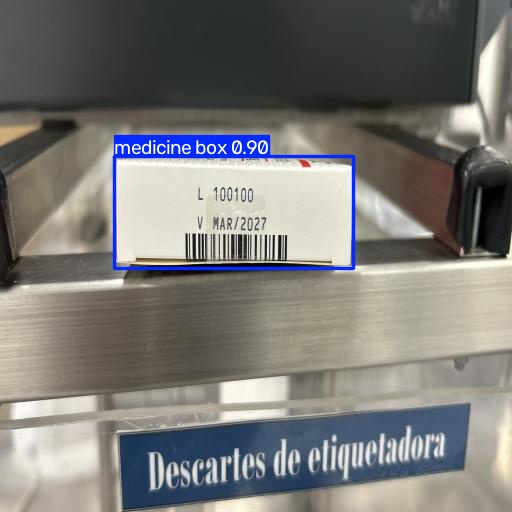

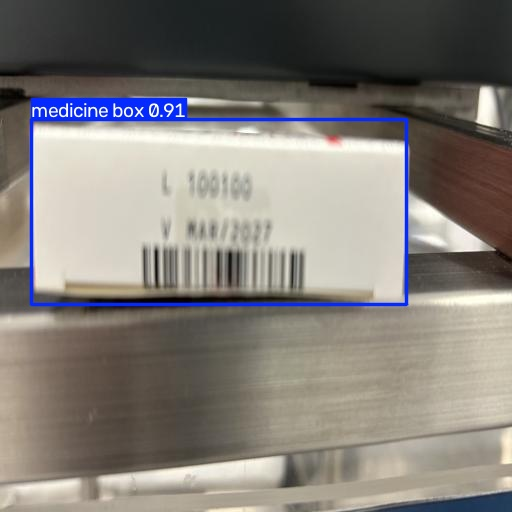

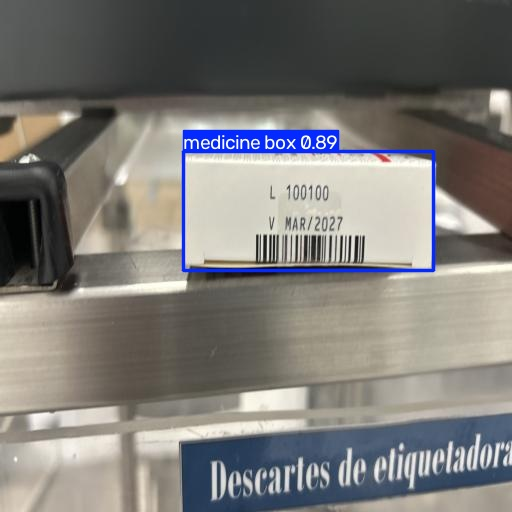

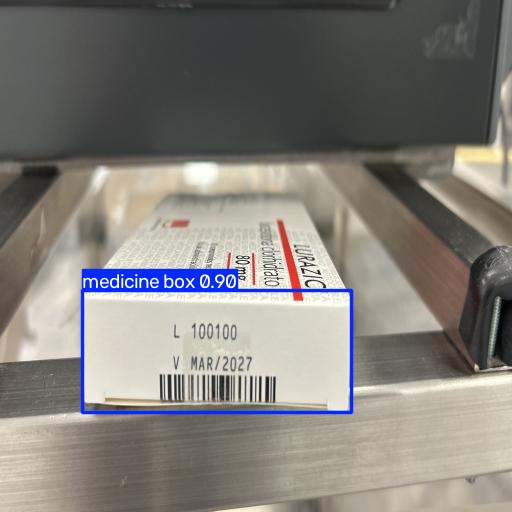

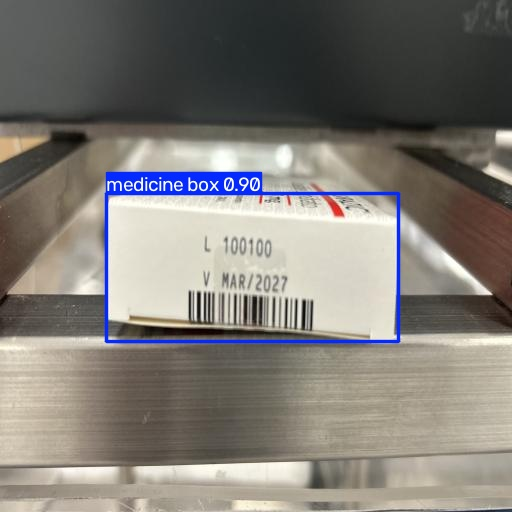

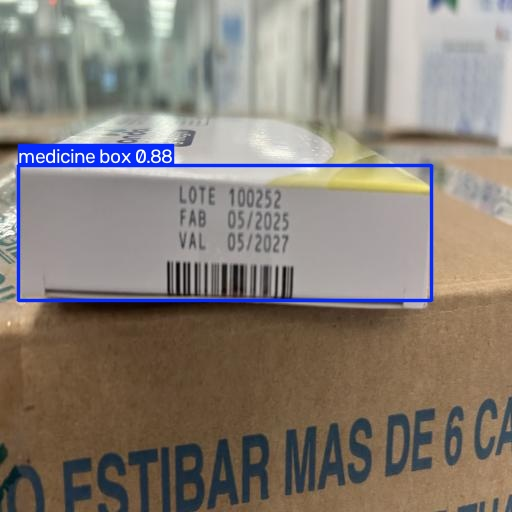

In [5]:
# detecções no conjunto de teste
import cv2
from google.colab.patches import cv2_imshow

_ = best.predict(f"{dataset.location}/test/images", save=True, conf=0.4, verbose=False)
pasta = max(glob.glob(f"{HOME}/runs/detect/predict*/"), key=os.path.getmtime)
for f in sorted(glob.glob(pasta + "*.jpg"))[:8]:
    cv2_imshow(cv2.imread(f))

Saving 13-08-2014-10-41-44-leite-com-formol.jpg to 13-08-2014-10-41-44-leite-com-formol.jpg
Saving images (2).jpg to images (2).jpg
Saving sddefault.jpg to sddefault.jpg
Saving images (1).jpg to images (1).jpg
Saving images.jpg to images.jpg
13-08-2014-10-41-44-leite-com-formol.jpg -> 1 etiqueta(s)


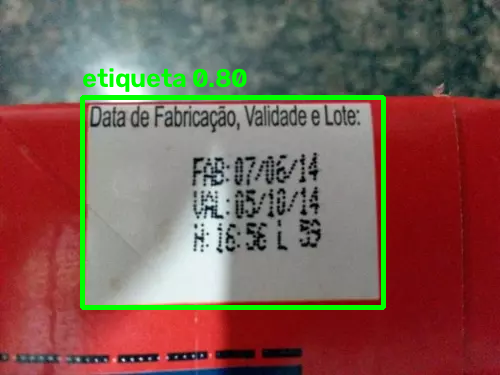

images (2).jpg -> 1 etiqueta(s)


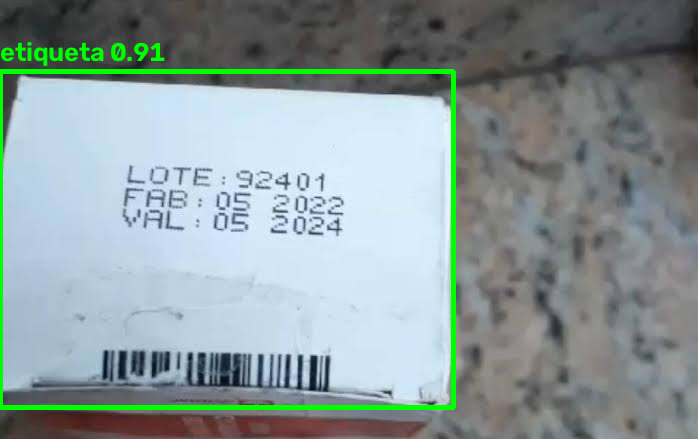

sddefault.jpg -> 3 etiqueta(s)


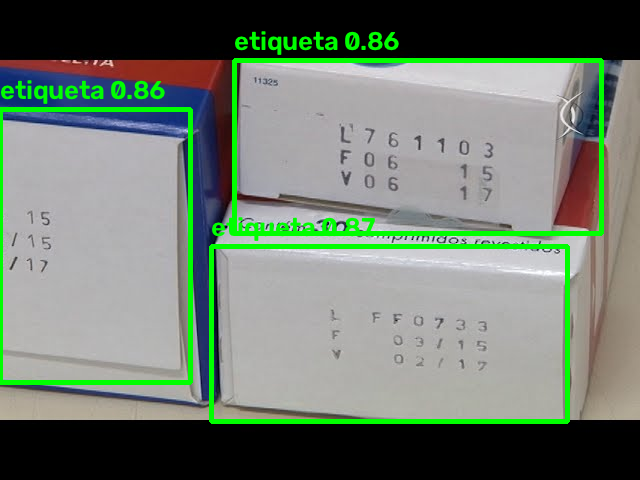

images (1).jpg -> 3 etiqueta(s)


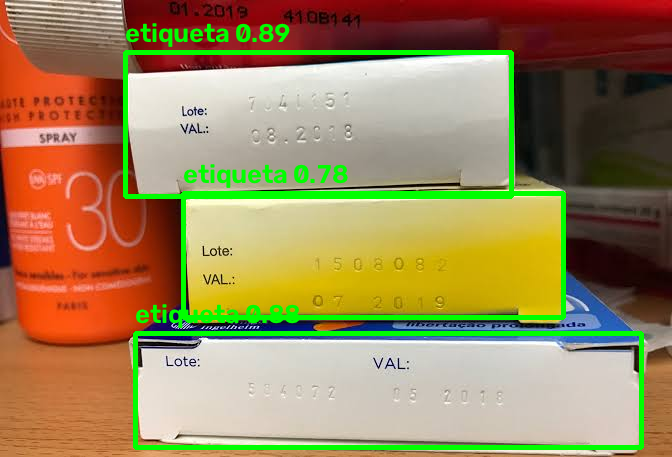

images.jpg -> 1 etiqueta(s)


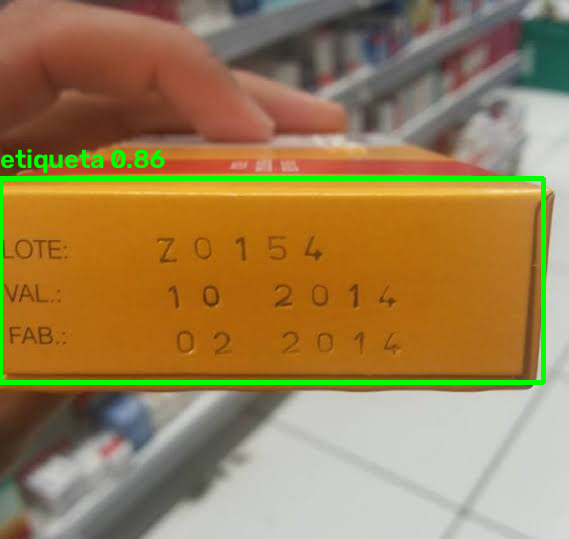

In [6]:
# Teste com as fotos: clicar em "Escolher arquivos" e suba fotos
# (rode depois da célula de métricas, que cria o modelo "best")
import cv2
from google.colab import files
from google.colab.patches import cv2_imshow

for nome in files.upload():
    img = cv2.imread(nome); h, w = img.shape[:2]
    r = best.predict(cv2.resize(img, (512, 512)), imgsz=512, conf=0.4, verbose=False)[0]
    for (x1, y1, x2, y2), c in zip(r.boxes.xyxy.tolist(), r.boxes.conf.tolist()):
        p1, p2 = (int(x1 * w / 512), int(y1 * h / 512)), (int(x2 * w / 512), int(y2 * h / 512))
        cv2.rectangle(img, p1, p2, (0, 255, 0), 3)
        cv2.putText(img, f"etiqueta {c:.2f}", (p1[0], max(25, p1[1] - 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 0), 2)
    print(nome, "->", len(r.boxes), "etiqueta(s)")
    cv2_imshow(cv2.resize(img, (900, int(h * 900 / w))) if w > 900 else img)

In [7]:
# Compara o modelo ANTIGO com o NOVO no MESMO conjunto de teste e gera a tabela pronta pro README
import os
from google.colab import files
from ultralytics import YOLO

print("Suba o best.pt ANTIGO (o primeiro modelo que você treinou):")
antigo = list(files.upload().keys())[0]

n_teste = len(os.listdir(f"{dataset.location}/test/images"))
linhas = ["| Modelo | Precisão | Revocação | mAP50 | mAP50-95 |", "|---|---|---|---|---|"]
for nome, pesos in {"v2 (antigo)": antigo, f"v{VERSAO} (novo)": PESOS}.items():
    m = YOLO(pesos).val(data=f"{dataset.location}/data.yaml", split="test", verbose=False).box
    linhas.append(f"| {nome} | {m.mp:.3f} | {m.mr:.3f} | {m.map50:.3f} | {m.map:.3f} |")
print(f"\nConjunto de teste: {n_teste} imagens (versão v{VERSAO}), as mesmas para os dois modelos\n")
print("\n".join(linhas))

Suba o best.pt ANTIGO (o primeiro modelo que você treinou):


Saving best.pt to best.pt
Ultralytics 8.4.190 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1366.7±429.8 MB/s, size: 25.0 KB)
val: Scanning /content/PI-VI---IVIS-3/test/labels.cache... 30 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 30/30 8.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.2it/s 0.9s
                   all         30         30      0.998          1      0.995       0.89
Speed: 4.0ms preprocess, 6.0ms inference, 0.0ms loss, 4.7ms postprocess per image
Results saved to /content/runs/detect/val-2
Ultralytics 8.4.190 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1028.6±376.2 MB/s, size: 19.4 KB

In [8]:
# Teste das fotos com mão: antigo x novo (conta em quantas fotos cada modelo achou alguma etiqueta)
import os, glob, cv2
from google.colab import files
from ultralytics import YOLO

if not os.path.exists("best.pt"):  # modelo antigo
    print("Suba o best.pt ANTIGO:"); files.upload()
PESOS = max(glob.glob("/content/runs/detect/train*/weights/best.pt"), key=os.path.getmtime)  # modelo novo
antigo_m, novo_m = YOLO("best.pt"), YOLO(PESOS)

print("Agora suba fotos com mão que NÃO estão no dataset:")
ok_a = ok_n = total = 0
for nome in files.upload():
    img = cv2.resize(cv2.imread(nome), (512, 512))
    a = len(antigo_m.predict(img, imgsz=512, conf=0.4, verbose=False)[0].boxes)
    n = len(novo_m.predict(img, imgsz=512, conf=0.4, verbose=False)[0].boxes)
    total += 1; ok_a += a > 0; ok_n += n > 0
    print(f"{nome}: antigo={a} etiqueta(s) | novo={n} etiqueta(s)")
print(f"\nAchou a etiqueta em {ok_a}/{total} (antigo) e {ok_n}/{total} (novo)")

Agora suba fotos com mão que NÃO estão no dataset:


Saving 13-08-2014-10-41-44-leite-com-formol.jpg to 13-08-2014-10-41-44-leite-com-formol (1).jpg
Saving images (2).jpg to images (2) (1).jpg
Saving sddefault.jpg to sddefault (1).jpg
Saving images (1).jpg to images (1) (1).jpg
Saving images.jpg to images (3).jpg
13-08-2014-10-41-44-leite-com-formol (1).jpg: antigo=0 etiqueta(s) | novo=1 etiqueta(s)
images (2) (1).jpg: antigo=1 etiqueta(s) | novo=1 etiqueta(s)
sddefault (1).jpg: antigo=3 etiqueta(s) | novo=3 etiqueta(s)
images (1) (1).jpg: antigo=4 etiqueta(s) | novo=3 etiqueta(s)
images (3).jpg: antigo=0 etiqueta(s) | novo=1 etiqueta(s)

Achou a etiqueta em 3/5 (antigo) e 5/5 (novo)


13-08-2014-10-41-44-leite-com-formol (1).jpg (vermelho = antigo, verde = novo)


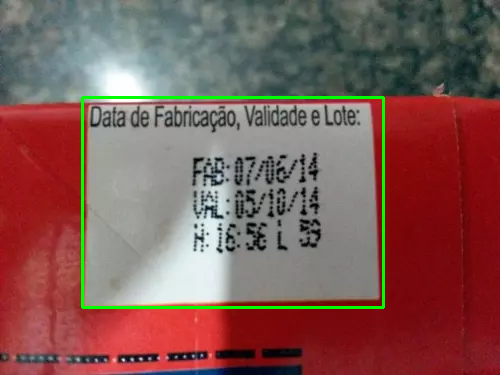

13-08-2014-10-41-44-leite-com-formol.jpg (vermelho = antigo, verde = novo)


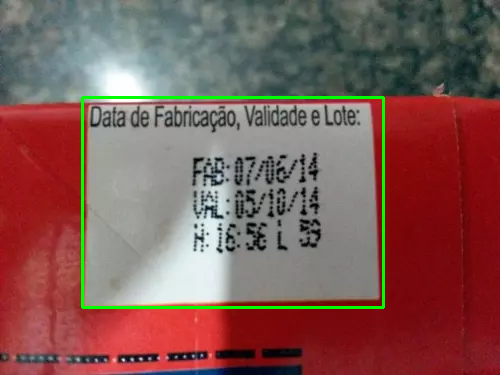

images (1) (1).jpg (vermelho = antigo, verde = novo)


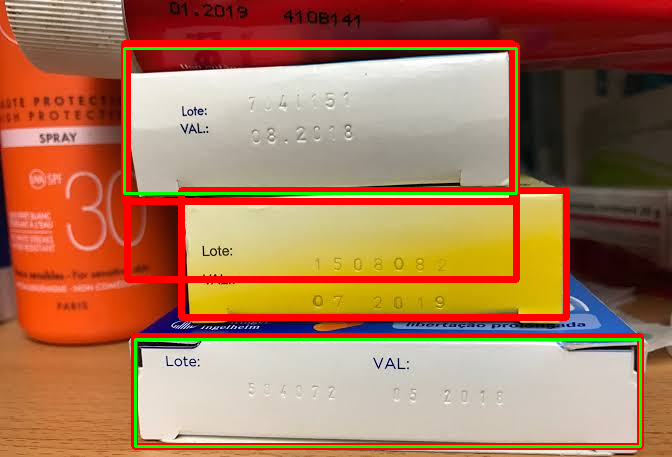

images (1).jpg (vermelho = antigo, verde = novo)


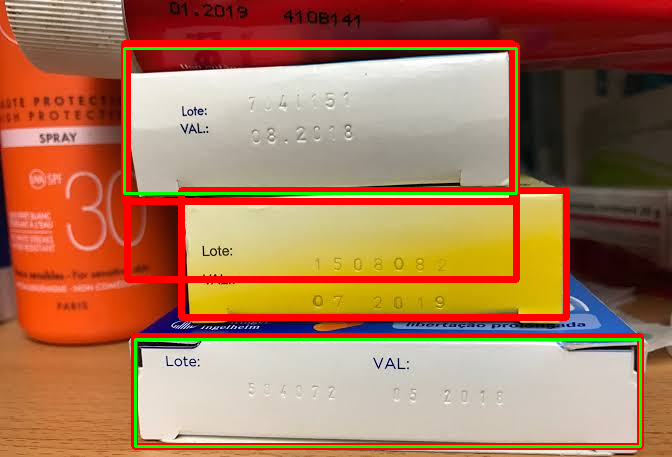

images (2) (1).jpg (vermelho = antigo, verde = novo)


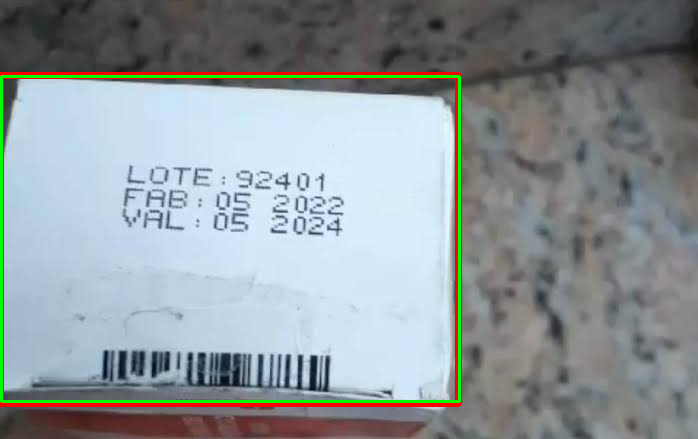

images (2).jpg (vermelho = antigo, verde = novo)


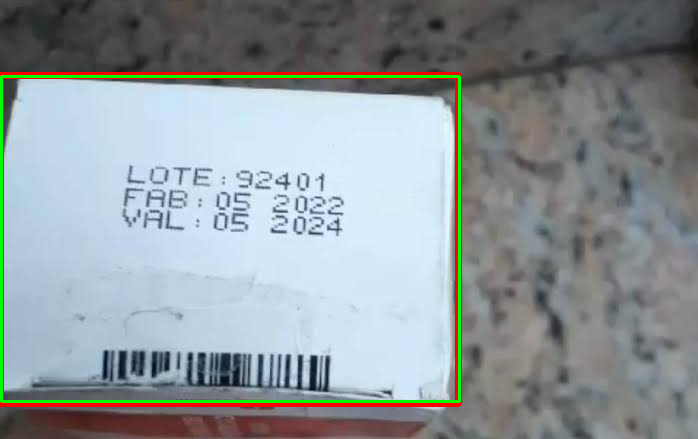

images (3).jpg (vermelho = antigo, verde = novo)


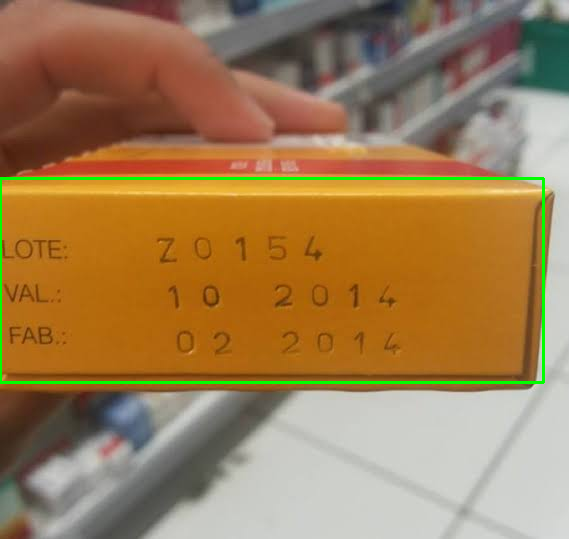

images.jpg (vermelho = antigo, verde = novo)


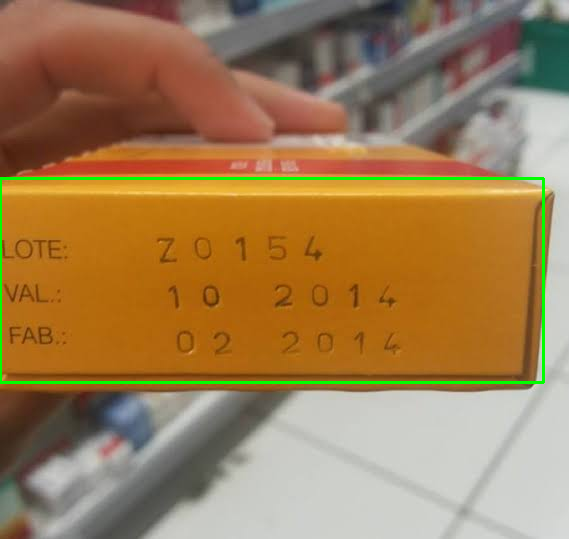

sddefault (1).jpg (vermelho = antigo, verde = novo)


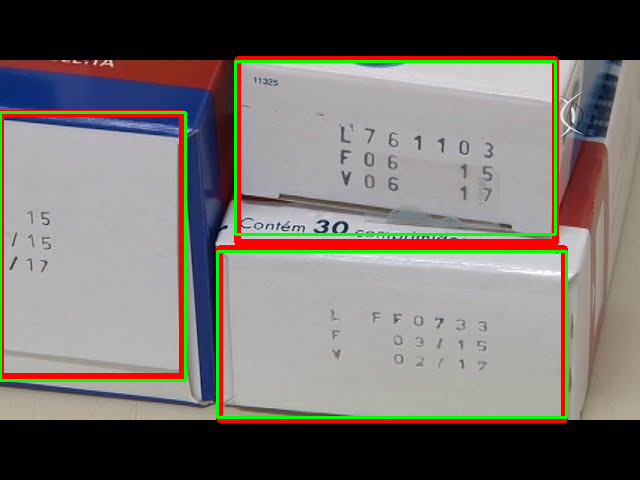

sddefault.jpg (vermelho = antigo, verde = novo)


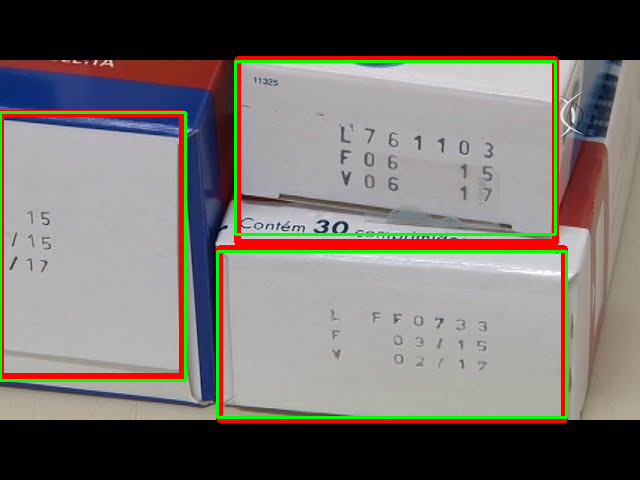

In [9]:
# CHECAGEM: caixas do antigo (vermelho) e do novo (verde) em cada foto que você subiu
from google.colab.patches import cv2_imshow

for nome in sorted(glob.glob("*.jpg")):
    img = cv2.imread(nome); h, w = img.shape[:2]
    for modelo, cor, esp in ((antigo_m, (0, 0, 255), 5), (novo_m, (0, 255, 0), 2)):
        r = modelo.predict(cv2.resize(img, (512, 512)), imgsz=512, conf=0.4, verbose=False)[0]
        for x1, y1, x2, y2 in r.boxes.xyxy.tolist():
            cv2.rectangle(img, (int(x1 * w / 512), int(y1 * h / 512)), (int(x2 * w / 512), int(y2 * h / 512)), cor, esp)
    print(nome, "(vermelho = antigo, verde = novo)")
    cv2_imshow(cv2.resize(img, (700, int(h * 700 / w))) if w > 700 else img)

In [ ]:
# Baixa o modelo novo
import shutil
from google.colab import files

novo = f"best_v{VERSAO}.pt"
shutil.copy(PESOS, novo)
files.download(novo)